# Numerical in-context learning on attention graphs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vcnoel/spectral-trust/blob/main/notebooks/05_numerical_icl.ipynb)

Bao, Qi, Liu, Arora, Sarfati, Boullé and Earls, *A Graph Signal Processing
Perspective on Numerical Sequence Representations in LLM In-Context Learning*
(arXiv 2608.03015, EACL 2027), serialise number sequences of increasing
dynamical complexity and read each layer's attention as a graph on the
tokens, with the hidden states as signals on it. As the context grows, simple
inputs give globally connected graphs and smooth hidden states; chaotic inputs
give localised graphs with more high-frequency energy.

`spectral_trust.numeric` packages their construction, and two library tools
take the study one step further. This notebook shows the toolkit on a small
model, Qwen2.5-0.5B, on a CPU:

1. serialising a numeric sequence and reading the model's next-value
   distribution;
2. the paper's spectral contrast between simple and complex dynamics;
3. `st.confound_audit`: what the diagnostics add to simpler covariates;
4. `st.edit_with_controls`: a graph-frequency edit next to matched controls
   of the same size.

It is a demonstration of the interface, not a reproduction of the paper: one
small model, four families, three realisations each. The use-case page
[Numerical in-context learning](https://vcnoel.github.io/spectral-trust/use-cases/numerical-icl/)
has the full pilot on Llama-3.2-1B, the smallest model of the paper.

**Runtime:** CPU is enough (Colab: *Runtime > Change runtime type > CPU*).
The first run downloads Qwen2.5-0.5B (about 1 GB); after that the notebook
runs in a few minutes with 4 threads.

In [1]:
# In Colab, install spectral-trust 0.5.3; 0.5.1 added spectral_trust.numeric,
# st.confound_audit and st.edit_with_controls.
import sys

if "google.colab" in sys.modules:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spectral-trust==0.5.3"],
                   check=True)

In [2]:
import os
os.environ.setdefault("TQDM_DISABLE", "1")          # no progress bars in the outputs

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import Markdown, display

import spectral_trust as st
from spectral_trust.numeric import (next_value_distribution, profile_from_outputs, quantize,
                                    repeat_fraction, serialize, value_spans)

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
torch.set_num_threads(4)
_ = torch.set_grad_enabled(False)
print("spectral-trust", st.__version__, "| torch", torch.__version__,
      "| transformers", transformers.__version__)

MODEL = "Qwen/Qwen2.5-0.5B"     # any causal LM; "meta-llama/Llama-3.2-1B" is gated
sm = st.SpectralModel.from_pretrained(MODEL, device="cpu")
model, tok = sm.model.eval(), sm.tokenizer
print(sm)

spectral-trust 0.5.0 | torch 2.11.0+cu128 | transformers 5.2.0


SpectralModel('Qwen/Qwen2.5-0.5B', 24 layers, 14 heads, normalization='sym')


## 1. Serialising a numeric sequence

The paper's format (also that of Gruver et al. 2023 and Liu et al. 2024):
each trajectory is rescaled to [50, 950], rounded, written as zero-padded
three-digit integers and followed by a comma. `quantize` takes the bounds of
the full 1000-step run, so a prefix keeps the same mapping at every context
length. The families here are a constant, the logistic map at r = 3.5
(period 4) and r = 3.566 (period 16), and the chaotic logistic map at r = 4.

In [3]:
def logistic(r, x, n):
    out = np.empty(n)
    for t in range(n):
        out[t] = x
        x = r * x * (1 - x)
    return out


def family(name, seed, n=100):
    """The first n values of one realisation, quantised on its 1000-step run."""
    x0 = np.random.default_rng(1000 + seed).uniform(0.3, 0.7)
    if name == "constant":
        return np.full(n, int(round(50 + 900 * x0)))
    r, period = {"period 4": (3.5, 4), "period 16": (3.566, 16), "chaotic": (4.0, None)}[name]
    if period is None:
        return quantize(logistic(r, x0, 1000))[:n]
    start = 10000 + seed % period                     # settled on the orbit, phase by seed
    return quantize(logistic(r, x0, start + 1000)[start:])[:n]


q = family("chaotic", 0)
text = serialize(q[:6])
sp = value_spans(tok, text)
print(text)
print([tok.decode([i]) for i in sp.input_ids])
print("value spans", sp.values, "| separators", sp.separators, "| special tokens", sp.special)

508,950,051,054,067,116,
['5', '0', '8', ',', '9', '5', '0', ',', '0', '5', '1', ',', '0', '5', '4', ',', '0', '6', '7', ',', '1', '1', '6', ',']
value spans [(0, 3), (4, 7), (8, 11), (12, 15), (16, 19), (20, 23)] | separators [3, 7, 11, 15, 19, 23] | special tokens []


`value_spans` locates each value's tokens. Qwen2.5 writes one token per digit
and adds no BOS token, so its first token plays the attention sink's role.
`next_value_distribution` reads the model's distribution over the next value
000 to 999: one restricted softmax when every value is one token (Llama 3),
and otherwise the digit-wise probabilities composed hierarchically,
P(v) = P(d1) P(d2 | d1) P(d3 | d1 d2), on the prompt's key-value cache.

In [4]:
for name in ("constant", "period 4", "period 16", "chaotic"):
    q = family(name, 0, 51)
    ids = torch.tensor([value_spans(tok, serialize(q[:50])).input_ids])
    d = next_value_distribution(model, ids, tok)
    print(f"{name:9s}  next value {q[50]:3d} | mode {d.mode:3d}, P(next value) "
          f"{np.exp(d.logprob(q[50])):.2f}, entropy {d.entropy:.2f} nats, std {d.std:5.1f}")

constant   next value 508 | mode 508, P(next value) 1.00, entropy 0.02 nats, std   5.3


period 4   next value  50 | mode  50, P(next value) 1.00, entropy 0.02 nats, std   6.1


period 16  next value  50 | mode  50, P(next value) 0.99, entropy 0.10 nats, std  17.5


chaotic    next value 757 | mode 875, P(next value) 0.00, entropy 6.89 nats, std 278.0


The model continues the constant and the periodic inputs almost
deterministically (entropy 0.02 to 0.10 nats) and is close to uniform on the
chaotic map (6.89 nats; uniform over 1000 values: 6.91).

## 2. The spectral contrast: simple against complex dynamics

`profile_from_outputs` builds the paper's graph at every layer from one
forward pass: the dropped positions leave the graph and each attention row is
renormalised over the remaining keys, heads are averaged after
symmetrisation, and the hidden states entering the layer are the signal. It
returns the normalized Fiedler value λ2, the high-frequency energy ratio HFER
(share of the signal's energy in the top half of the combinatorial-Laplacian
modes) and exp(SE), the effective number of graph Fourier modes, each
averaged over layers. The paper drops BOS; for a model without BOS, drop its
first token, the sink (`drop=(0,)`, the default).

Three realisations of each family at 25, 50 and 100 values (100, 200 and 400
tokens). Next to the diagnostics, each row keeps the covariates of section 3:
the attention to the sink, the effective rank of the middle layer's hidden
states, the number of distinct values and the repeat fraction (the share of
the sequence an induction mechanism can copy).

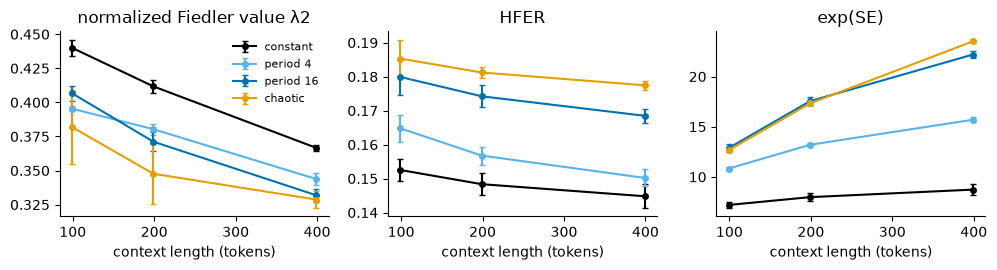

,fiedler,hfer,exp_se,sink_mass,effective_rank,repeat_fraction
family,,,,,,
constant,0.367,0.145,8.732,0.335,17.450,0.990
period 4,0.344,0.150,15.696,0.305,39.048,0.959
period 16,0.332,0.168,22.191,0.301,89.843,0.837
chaotic,0.329,0.177,23.510,0.337,143.835,0.020


In [5]:
FAMILIES = ["constant", "period 4", "period 16", "chaotic"]
COLORS = {"constant": "#000000", "period 4": "#56B4E9", "period 16": "#0072B2",
          "chaotic": "#E69F00"}
rows = []
for n_values in (25, 50, 100):
    for name in FAMILIES:
        for seed in range(3):
            q = family(name, seed, n_values)
            sp = value_spans(tok, serialize(q))
            out = model(input_ids=torch.tensor([sp.input_ids]),
                        output_attentions=True, output_hidden_states=True)
            drop = sp.special or [0]                  # no BOS: the first token is the sink
            prof = profile_from_outputs(out.attentions, out.hidden_states, drop=drop)
            keep = [p for p in range(len(sp.input_ids)) if p not in drop]
            middle = out.hidden_states[len(out.hidden_states) // 2][0, keep]
            rows.append(dict(family=name, seed=seed, n_values=n_values, n_tokens=len(keep),
                             **prof.mean, effective_rank=st.effective_rank(middle),
                             log_distinct=np.log(len(set(q.tolist()))),
                             repeat_fraction=repeat_fraction(q)))
            del out
df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, (m, label) in zip(axes, [("fiedler", "normalized Fiedler value λ2"),
                                 ("hfer", "HFER"), ("exp_se", "exp(SE)")]):
    for name in FAMILIES:
        g = df[df.family == name].groupby("n_tokens")[m]
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), color=COLORS[name], marker="o",
                    ms=4, capsize=2, label=name)
    ax.set_title(label)
    ax.set_xlabel("context length (tokens)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
(df[df.n_values == 100].groupby("family", sort=False)
 [["fiedler", "hfer", "exp_se", "sink_mass", "effective_rank", "repeat_fraction"]]
 .mean().round(3))

On Qwen2.5-0.5B the paper's ordering appears in HFER at every length
(constant < period 4 < period 16 < chaotic), and at 400 tokens the chaotic
inputs also have the lowest λ2 (0.329) and the highest exp(SE) (23.5), with
period 16 close behind on both. Error bars: ±1 SD over the three
realisations. The covariates follow the same ordering: the effective rank of
the hidden states grows from 17 (constant) to 144 (chaotic), and the repeat
fraction falls from 0.99 to 0.02.

## 3. Confound audit

Dynamical complexity moves simpler quantities with it: the number of distinct
values, how much of the sequence an induction mechanism can copy, the
attention sink and the effective rank of the hidden states. A diagnostic
that tracks complexity should say something these covariates do not.
`st.confound_audit` reports, for each readout, the AUROC of chaotic against
the other families raw and after the readout's linear dependence on the
covariates is removed, the partial correlation, the cross-validated AUROC
of the covariates alone and the gain from adding the readout. The italic rows
give each covariate's own AUROC, the baseline a readout has to beat.
Intervals are bootstrap intervals that resample realisations whole (the same
realisation appears at three lengths); with 36 inputs they are wide.

In [6]:
y = (df.family == "chaotic").astype(int).values
readouts = {m: df[m].values for m in ("fiedler", "hfer", "exp_se")}
realisation = (df.family + "/" + df.seed.astype(str)).values
for title, keys in [("length, sink mass, effective rank",
                     ["n_tokens", "sink_mass", "effective_rank"]),
                    ("the same, with distinct values and repeat fraction",
                     ["n_tokens", "sink_mass", "effective_rank", "log_distinct",
                      "repeat_fraction"])]:
    res = st.confound_audit(readouts, y, {k: df[k].values for k in keys},
                            groups=realisation, n_boot=500)
    display(Markdown(f"**Covariates: {title}**\n\n" + res.to_markdown()))

**Covariates: length, sink mass, effective rank**

| readout | AUROC raw | AUROC after covariates | partial r | CV AUROC, covariates | CV AUROC gain |
|---|---|---|---|---|---|
| fiedler | 0.23 [0.08, 0.36] | 0.44 [0.27, 0.69] | -0.57 [-0.77, -0.33] | 1.00 [1.00, 1.00] | 0.00 [0.00, 0.00] |
| hfer | 0.95 [0.87, 1.00] | 0.52 [0.35, 0.68] | 0.16 [-0.32, 0.60] | 1.00 [1.00, 1.00] | -0.00 [-0.02, 0.00] |
| exp_se | 0.76 [0.62, 0.89] | 0.53 [0.39, 0.66] | 0.18 [-0.17, 0.55] | 1.00 [1.00, 1.00] | 0.00 [0.00, 0.00] |
| *n_tokens (covariate)* | 0.50 [0.50, 0.50] | | | | |
| *sink_mass (covariate)* | 0.77 [0.67, 0.85] | | | | |
| *effective_rank (covariate)* | 0.89 [0.77, 1.00] | | | | |

**Covariates: the same, with distinct values and repeat fraction**

| readout | AUROC raw | AUROC after covariates | partial r | CV AUROC, covariates | CV AUROC gain |
|---|---|---|---|---|---|
| fiedler | 0.23 [0.08, 0.36] | 0.51 [0.28, 0.71] | -0.50 [-0.76, -0.09] | 1.00 [1.00, 1.00] | 0.00 [0.00, 0.00] |
| hfer | 0.95 [0.87, 1.00] | 0.42 [0.12, 0.77] | -0.38 [-0.65, 0.09] | 1.00 [1.00, 1.00] | 0.00 [0.00, 0.00] |
| exp_se | 0.76 [0.62, 0.89] | 0.54 [0.29, 0.74] | 0.27 [0.09, 0.46] | 1.00 [1.00, 1.00] | 0.00 [0.00, 0.00] |
| *n_tokens (covariate)* | 0.50 [0.50, 0.50] | | | | |
| *sink_mass (covariate)* | 0.77 [0.67, 0.85] | | | | |
| *effective_rank (covariate)* | 0.89 [0.77, 1.00] | | | | |
| *log_distinct (covariate)* | 1.00 [1.00, 1.00] | | | | |
| *repeat_fraction (covariate)* | 0.00 [0.00, 0.00] | | | | |

Raw, HFER separates chaotic from the other inputs with an AUROC of 0.95 and
λ2 with 0.23 (below 0.5: lower for chaotic inputs, as in the paper). On these
four families the covariates separate the two groups as well: the effective
rank alone reaches 0.89, the number of distinct values 1.00 (the repeat
fraction's 0.00 is a perfect separation in the other direction), and the
cross-validated covariates 1.00, so here the diagnostics cannot add to them
(gain 0.00) and their AUROC returns to about 0.5 once the covariates are
removed. λ2 keeps a partial correlation of −0.57 [−0.77, −0.33] with the label
given length, sink mass and effective rank. Four families make this a
demonstration of the table. The use-case page adds families that pull the
covariates apart (a shuffled period, a sine, noise and a random walk) and
finds on Llama-3.2-1B that λ2 keeps part of the complexity ordering beyond
them.

## 4. One edit and its matched controls

The paper reports no intervention and leaves the causal question open:
"frequency-band ablations could test the functional importance of particular
bands". `st.edit_with_controls` runs one graph-frequency edit and, at the same
strengths, controls whose edit has the same norm on every item, then reads the
model with any readout. Here the edit is a causal low-pass filter of the
residual stream after the middle block, along that block's attention graph,
at the numeric tokens of chaotic sequences: `X' = X + s (g(L) X − X)`. If the
smooth hidden states of simple inputs are what makes their continuation
confident, smoothing a chaotic sequence should lower the entropy of its
next-value distribution beyond the controls:

- `permuted`: the same filter on the attention graph with its nodes permuted
  (position 0 kept): the same edge weights, unrelated token structure;
- `path`: the same filter on the chain graph over positions;
- `scaling`: no graph, the residual shrunk at the same positions.

`token_span=(1, None)` keeps the first token, the sink, out of the graph:
its residual norm is far above the others', and a low-pass filter would
spread it into every position. `max_relative_edit=0.3` skips strengths whose
edit exceeds 30% of the residual's norm.

In [7]:
items, positions = [], []
for seed in range(6):
    sp = value_spans(tok, serialize(family("chaotic", 10 + seed, 100)))   # unseen realisations
    items.append(sp.input_ids)
    positions.append([p for p in sp.numeric_positions if p >= 1])


def readout(m, ids):
    return next_value_distribution(m, ids, tok, min_prob=1e-3).summary()


LAYER = sm.n_layers // 2
res = st.edit_with_controls(model, items, readout, layer=LAYER, kind="lowpass", cutoff=0.5,
                            strengths=(0.2, 0.4), positions=positions, token_span=(1, None),
                            controls=("permuted", "path", "scaling"), max_relative_edit=0.3)
print(f"edit after block {LAYER} of {sm.n_layers}; unedited entropy "
      f"{np.mean([b['entropy'] for b in res.baseline]):.2f} nats "
      f"(uniform over 1000 values: 6.91); skipped strengths: {res.skipped or 'none'}")
table = pd.DataFrame(res.summary(["entropy", "std"], n_boot=1000))
cols = ["condition", "strength", "relative_edit", "metric", "delta", "delta_lo", "delta_hi",
        "target_minus", "target_minus_lo", "target_minus_hi"]
table[table.metric == "entropy"][cols].round(3)

edit after block 12 of 24; unedited entropy 6.43 nats (uniform over 1000 values: 6.91); skipped strengths: none


,condition,strength,relative_edit,metric,delta,delta_lo,delta_hi,target_minus,target_minus_lo,target_minus_hi
0,target,0.2,0.122,entropy,0.017,-0.056,0.079,NaN,NaN,NaN
2,permuted,0.2,0.122,entropy,0.055,0.008,0.124,-0.037,-0.082,-0.002
4,path,0.2,0.122,entropy,-0.007,-0.091,0.049,0.025,0.005,0.045
6,scaling,0.2,0.122,entropy,-0.034,-0.093,0.004,0.052,-0.055,0.169
8,target,0.4,0.244,entropy,0.018,-0.115,0.122,NaN,NaN,NaN
10,permuted,0.4,0.244,entropy,0.109,0.029,0.193,-0.091,-0.267,-0.001
12,path,0.4,0.244,entropy,-0.039,-0.269,0.107,0.057,0.003,0.157
14,scaling,0.4,0.244,entropy,-0.051,-0.157,0.045,0.069,-0.163,0.286


On six sequences the attention-graph low-pass leaves the entropy unchanged
within its interval (+0.02 [−0.06, +0.08] nats at a relative edit of 0.12, and
+0.02 [−0.12, +0.12] at 0.24): smoothing along the attention graph does not
make the prediction more confident. At equal norm, the same filter on the
permuted graph raises the entropy more (target minus permuted −0.04 [−0.08,
−0.002] and −0.09 [−0.27, −0.001]), the path graph and plain shrinking leave it
unchanged, and the attention filter raises it slightly more than the path
filter (target minus path +0.025 [+0.005, +0.045] and +0.057 [+0.003,
+0.157]). The use-case page finds the same pattern against the permuted
graph on 24 sequences of Llama-3.2-1B and Qwen3-0.6B. The model is close to
uniform on
chaotic continuations at this length (6.43 nats against 6.91), which leaves
the entropy little room to move, and six sequences make this a demonstration
of the interface, not a result. `res.values`, `res.deltas` and `res.to_dict()`
give the per-sequence readouts.

## Going further

- Swap `MODEL` for `"meta-llama/Llama-3.2-1B"` (gated: a Hugging Face token
  with access to Llama 3.2), the smallest model of the paper, whose tokenizer
  writes each three-digit value as one token; `next_value_distribution` then
  reads one restricted softmax.
- `profile_from_outputs(..., groups=...)` pools the digit tokens of each value
  into one node, and `pairing="output"` pairs each layer with the states it
  produces instead of those entering it.
- `edit_with_controls(edit="band_patch", source=..., modes=(lo, hi))` patches
  one band of the clean run's attention basis into a corrupt run, with
  permuted-graph, path, random-subspace and plain-patching controls of the
  same norm.
- The use-case page
  [Numerical in-context learning](https://vcnoel.github.io/spectral-trust/use-cases/numerical-icl/)
  runs all of this at scale on Llama-3.2-1B and Qwen3-0.6B: 14 families
  including shuffled, sine, noise and random-walk controls, a steering dose
  on 24 sequences, and frequency-resolved patching at three layers.